# Plein Tarif — exploration des données

Ce notebook explore les données brutes et nettoyées avant l'analyse : formats des fichiers annuels, effet de chaque règle de nettoyage, structure du panel quotidien, couverture des enseignes et cohérence avec les moyennes officielles du ministère.

Pré-requis : `python run.py all` (ou au moins `download`, `parse`, `clean`, `enrich`, `model`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import plotly.express as px
from IPython.display import Image, display
from plein_tarif import charts as ch
from plein_tarif.model import connect_db
pd.set_option("display.width", 160)
con = connect_db()
def show(fig, w=1100, h=450):
    display(Image(fig.to_image(format="png", width=w, height=h)))

## 1. Les fichiers annuels : un format qui change

Chaque année est un XML (ISO-8859-1) d'environ 300 à 390 Mo. Le profilage montre deux unités de prix : en **millièmes d'euro** jusqu'en 2021 (`1328` = 1,328 €) puis en **euros** à partir de 2022 (`1.572`). L'unité est détectée par fichier (part des valeurs contenant un point), jamais déduite de l'année.

In [2]:
rep = pd.read_csv(ROOT / "data/parsed/parse_report.csv")
rep[["year", "encoding", "price_unit", "coord_divisor", "stations", "stations_without_coordinates",
     "price_records", "empty_price_elements", "integer_values_in_euro_file", "median_price_eur"]]

,year,encoding,price_unit,coord_divisor,stations,stations_without_coordinates,price_records,empty_price_elements,integer_values_in_euro_file,median_price_eur
0,2019,ISO-8859-1,thousandth,100000.0,12969,69,4211139,3295,0,1.483
1,2020,ISO-8859-1,thousandth,100000.0,13188,69,3860225,3570,0,1.330
2,2021,ISO-8859-1,thousandth,100000.0,13386,69,4283692,3695,0,1.524
3,2022,ISO-8859-1,euro,100000.0,13645,69,5044596,4010,3256,1.806
4,2023,ISO-8859-1,euro,100000.0,13837,69,4683353,4177,3041,1.855
5,2024,ISO-8859-1,euro,100000.0,14162,69,4587613,4573,1205,1.769
6,2025,ISO-8859-1,euro,100000.0,14420,69,5297800,4658,642,1.686


## 2. Nettoyage : effet de chaque règle

In [3]:
clean = pd.read_csv(ROOT / "data/processed/cleaning_report.csv")
clean["removed_pct"] = (100 * clean["removed"] / clean["before"]).round(3)
clean

,rule,before,removed,after,removed_pct
0,P0 parsed records,31968418,0,31968418,0.000
1,P1 out of scope (overseas / unknown department),31968418,0,31968418,0.000
2,P2 non-positive price,31968418,0,31968418,0.000
3,P3 outside hard bounds,31968418,934,31967484,0.003
4,P4 duplicate station/fuel/timestamp,31967484,875,31966609,0.003
5,P5 more than 8.0 robust SD from daily median,31966609,40579,31926030,0.127
6,P6 isolated spike (typo corrected right away),31926030,16267,31909763,0.051


In [4]:
print(json.dumps(json.loads((ROOT / "data/processed/cleaning_report.json").read_text())["stations"], indent=1, ensure_ascii=False))

{
 "station_year_rows": 95607,
 "stations_unique": 14879,
 "stations_by_zone": {
  "mainland": 14719,
  "corsica": 158,
  "overseas": 2
 },
 "stations_unknown_department": 1,
 "station_year_rows_out_of_bbox": 484,
 "station_year_rows_missing_coords": 483,
 "stations_without_valid_coords": 138,
 "stations_motorway": 899,
 "stations_motorway_flag_changed": 20
}


## 3. Des changements de prix au panel quotidien

Les stations n'envoient un enregistrement que lorsqu'elles modifient (ou confirment) un prix. Le panel quotidien reporte le dernier prix connu au plus 7 jours. Distribution de l'ancienneté du prix reporté :

In [5]:
stale = con.execute("""SELECT staleness_days, count(*) AS n FROM fact_price_daily GROUP BY 1 ORDER BY 1""").df()
stale["share_pct"] = (100 * stale["n"] / stale["n"].sum()).round(2)
print(json.loads((ROOT / "data/processed/panel_report.json").read_text()))
stale

{'max_staleness_days': 7, 'panel_rows': 63068819, 'panel_series': 43203, 'panel_stations': 11382, 'filled_rows_share': 0.54934676991494, 'price_changes': 17633592, 'rows_by_fuel': {'Gazole': 19453388, 'SP98': 15716163, 'E10': 14914766, 'SP95': 6716328, 'E85': 4277688, 'GPLc': 1990486}}


,staleness_days,n,share_pct
0,0,28422167,45.07
1,1,9889022,15.68
2,2,7438597,11.79
3,3,5295178,8.40
4,4,4037473,6.40
5,5,3288231,5.21
6,6,2664595,4.22
7,7,2033556,3.22


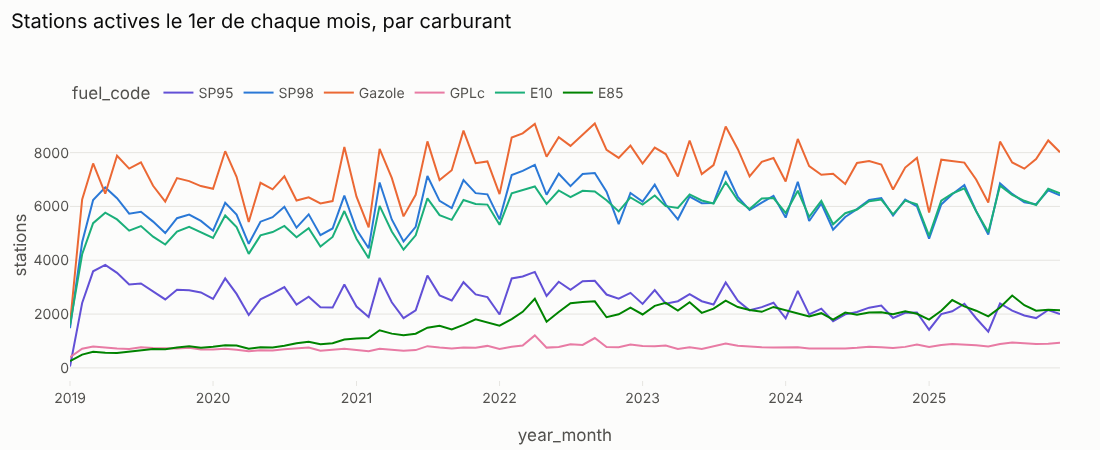

In [6]:
active = con.execute("""
    SELECT d.year_month, f.fuel_code, count(DISTINCT p.station_key) AS stations
    FROM fact_price_daily p JOIN dim_date d USING (date_key) JOIN dim_fuel f USING (fuel_key)
    WHERE d.date = date_trunc('month', d.date) GROUP BY ALL ORDER BY 1""").df()
fig = px.line(active, x="year_month", y="stations", color="fuel_code", color_discrete_map=ch.FUEL_COLORS,
              title="Stations actives le 1er de chaque mois, par carburant")
show(fig)

Le SP95-E10 progresse au détriment du SP95 ; l'E85 se développe nettement après 2022.

## 4. Distribution des prix et fréquence des mises à jour

In [7]:
dist = con.execute("""
    SELECT d.year, f.fuel_code, quantile_cont(p.price_ttc, [0.01, 0.25, 0.5, 0.75, 0.99]) AS q
    FROM fact_price_daily p JOIN dim_date d USING (date_key) JOIN dim_fuel f USING (fuel_key)
    WHERE f.is_main_fuel GROUP BY ALL ORDER BY 2, 1""").df()
dist[["p01", "p25", "p50", "p75", "p99"]] = pd.DataFrame(dist["q"].tolist()).round(3)
dist.drop(columns="q")

,year,fuel_code,p01,p25,p50,p75,p99
0,2019,E10,1.353,1.442,1.479,1.539,1.704
1,2020,E10,1.163,1.279,1.319,1.429,1.634
2,2021,E10,1.338,1.478,1.539,1.606,1.794
3,2022,E10,1.399,1.659,1.758,1.909,2.213
4,2023,E10,1.699,1.809,1.866,1.923,2.138
5,2024,E10,1.623,1.724,1.789,1.859,2.067
6,2025,E10,1.564,1.646,1.688,1.749,1.989
7,2019,Gazole,1.346,1.409,1.439,1.487,1.639
8,2020,Gazole,1.112,1.194,1.239,1.357,1.589
9,2021,Gazole,1.259,1.372,1.434,1.519,1.710


In [8]:
freq = con.execute("""
    SELECT d.year, f.fuel_code, count(*) / count(DISTINCT c.station_key) AS changes_per_station,
           median(c.hours_since_previous) AS median_hours_between_changes,
           median(abs(c.change)) * 100 AS median_abs_change_cts
    FROM fact_price_change c JOIN dim_date d USING (date_key) JOIN dim_fuel f USING (fuel_key)
    WHERE f.is_main_fuel GROUP BY ALL ORDER BY 2, 1""").df().round(2)
freq

,year,fuel_code,changes_per_station,median_hours_between_changes,median_abs_change_cts
0,2019,E10,85.01,24.15,1.0
1,2020,E10,79.85,24.00,1.0
2,2021,E10,96.22,24.00,1.0
3,2022,E10,122.47,24.30,2.0
4,2023,E10,95.00,26.50,1.0
5,2024,E10,91.22,24.24,1.0
6,2025,E10,110.75,24.00,1.0
7,2019,Gazole,74.51,33.65,1.0
8,2020,Gazole,73.06,28.14,1.0
9,2021,Gazole,87.78,24.54,1.0


Les stations changent leurs prix plus souvent depuis 2022 (crise puis habitudes de mise à jour quotidienne automatique), avec des variations médianes de 1 à 2 centimes.

## 5. Enseignes (OpenStreetMap)

In [9]:
rep = json.loads((ROOT / "data/processed/brand_match_report.json").read_text())
print({k: rep[k] for k in ["osm_fuel_stations", "radius_m", "matched", "match_rate", "match_rate_active_last_year", "ambiguous", "median_distance_m"]})
pd.read_csv(ROOT / "data/processed/brand_match_radius_sensitivity.csv")

{'osm_fuel_stations': 12539, 'radius_m': 75, 'matched': 6906, 'match_rate': 0.6067, 'match_rate_active_last_year': 0.6237, 'ambiguous': 55, 'median_distance_m': 33.25}


,radius_m,match_rate_all,match_rate_active_last_year
0,25,0.223,0.225
1,50,0.459,0.468
2,75,0.607,0.624
3,100,0.676,0.695
4,150,0.749,0.771
5,200,0.791,0.812
6,300,0.842,0.865
7,500,0.898,0.919


Les coordonnées officielles sont souvent approximatives (géocodage de l'adresse) : à 75 m, 62 % des stations actives en 2025 sont rattachées à une station OSM ; à 150 m, 77 %. Le rayon reste à 75 m par prudence (moins de faux rattachements) ; il est configurable.

## 6. Cohérence avec les moyennes officielles (DGEC)

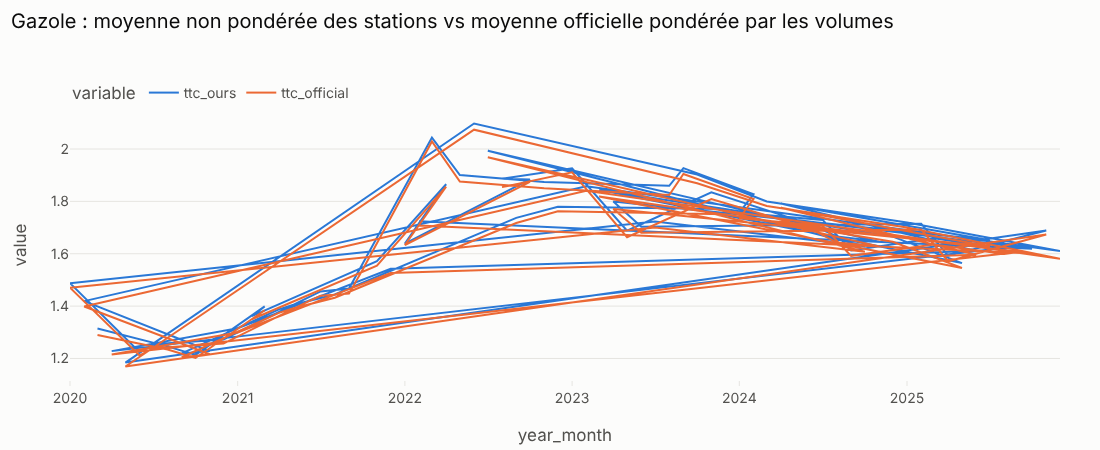

gap_mean_cts                                           gap_median_cts                                          
                 count  mean   std   min   25%   50%   75%   max          count  mean   std   min   25%   50%   75%   max
fuel_code                                                                                                                
E10               72.0  1.28  0.44  0.22  1.07  1.31  1.51  2.92           72.0 -0.90  0.62 -2.28 -1.35 -0.96 -0.52  1.17
E85               72.0  2.03  0.73 -0.74  1.65  2.17  2.51  3.59           72.0  0.93  1.30 -2.64  0.03  0.65  2.05  3.54
GPLc              72.0  2.07  0.68  0.39  1.65  2.07  2.63  3.78           72.0  1.16  0.66 -0.15  0.71  1.09  1.58  2.80
Gazole            72.0  1.90  0.56  0.54  1.53  1.87  2.27  3.50           72.0 -0.31  0.84 -1.80 -0.96 -0.38  0.16  2.06
SP95              72.0  1.50  0.59  0.17  1.19  1.46  1.77  3.16           72.0  0.42  0.69 -0.67 -0.01  0.36  0.71  2.61
SP98              72.0  1.22  0.34  0.33  1.06  1.21  1.37  2.30           72.0 -1.19  0.79 -2.78 -1.82 -1.23 -0.83  0.75

In [10]:
cmp_ = pd.read_csv(ROOT / "reports/tables/official_comparison_monthly.csv")
g = cmp_[cmp_["fuel_code"] == "Gazole"]
fig = px.line(g.melt(id_vars="year_month", value_vars=["ttc_ours", "ttc_official"]), x="year_month", y="value",
              color="variable", title="Gazole : moyenne non pondérée des stations vs moyenne officielle pondérée par les volumes")
show(fig)
cmp_.groupby("fuel_code")[["gap_mean_cts", "gap_median_cts"]].describe().round(2)

Notre moyenne (non pondérée, toutes stations, Corse incluse) est 1 à 2 centimes au-dessus de la moyenne officielle, qui est pondérée par les parts de marché des distributeurs (méthodologie DGEC) : la grande distribution, moins chère, vend la majorité des volumes. La médiane des stations est, elle, très proche du chiffre officiel. La corrélation mensuelle est de 1,00.

In [11]:
con.close()